<a href="https://colab.research.google.com/github/jorgecaraveobalderas-beep/Class-Files/blob/main/Caraveo_Jorge_EDA_predictivo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Actividad: análisis exploratorio de datos para analítica predictiva
## Caso: suscripción a un depósito a plazo tras una llamada de telemarketing bancario

Programación para Analítica Descriptiva y Predictiva · Tema : EDA con Analítica Predictiva
Maestría en Inteligencia Artificial y Analítica de Datos · UACJ

**Nombre del estudiante:** ___Jorge Alberto Caraveo Balderas_____________  

**Matrícula:** _#274702_____________

**Fecha:** ___05/10/2026___________

## Propósito

Aplicar, de forma individual y sobre un conjunto de datos nuevo, el procedimiento de análisis exploratorio para analítica predictiva revisado en el notebook guiado del caso Telco. El producto de la actividad es una **hoja de decisiones** de preprocesamiento y modelado, sustentada en evidencia obtenida con el código.

No se entrena ningún modelo en esta actividad.

## Instrucciones de entrega

1. Completa las celdas de código y las de texto marcadas con **Tu predicción**, **Tu observación** o **Tu respuesta**.
2. Antes de entregar, ejecuta el notebook completo con *Kernel > Restart & Run All*. El notebook debe ejecutarse de principio a fin sin errores.
3. Guarda el archivo como `Apellido_Nombre_EDA_predictivo.ipynb` y entrégalo en el medio indicado por el profesor.
4. La actividad es individual. Las predicciones deben escribirse **antes** de ejecutar cada celda de código.

## Reglas de trabajo

- Usa solo el conjunto `df` y las librerías ya importadas.
- Después de la división de la parte C, el conjunto `prueba` **no se utiliza** en ninguna celda.
- Usa `random_state=42` en toda operación aleatoria, para que los resultados sean comparables.
- Las observaciones y las decisiones citan cifras obtenidas con tu propio código.

## Conjunto de datos y fuente

**Bank Marketing** (archivo `bank-additional-full.csv`), del repositorio UCI de aprendizaje automático. Cada fila es un contacto telefónico de una campaña de marketing directo de un banco portugués. El conjunto contiene 41,188 contactos ordenados por fecha, de mayo de 2008 a noviembre de 2010, y 21 columnas.


**Problema predictivo.** Clasificación binaria: dadas las características de un cliente y del contexto de la campaña, predecir si el cliente contratará el depósito a plazo (`y`).

**Diccionario de datos**

| Columna | Contenido |
| --- | --- |
| `age` | Edad del cliente |
| `job`, `marital`, `education` | Ocupación, estado civil y escolaridad |
| `default`, `housing`, `loan` | Si tiene crédito en incumplimiento, crédito hipotecario y préstamo personal |
| `contact` | Medio de contacto: `cellular` o `telephone` |
| `month`, `day_of_week` | Mes y día de la semana del último contacto de la campaña actual |
| `duration` | Duración de la última llamada, en segundos |
| `campaign` | Número de contactos con este cliente en la campaña actual, incluido el último |
| `pdays` | Días transcurridos desde el último contacto de una campaña anterior; `999` indica que no fue contactado antes |
| `previous` | Número de contactos antes de la campaña actual |
| `poutcome` | Resultado de la campaña anterior: `success`, `failure` o `nonexistent` |
| `emp.var.rate`, `cons.price.idx`, `cons.conf.idx`, `euribor3m`, `nr.employed` | Indicadores económicos trimestrales o mensuales: variación del empleo, índice de precios, índice de confianza del consumidor, tasa Euribor a 3 meses y número de empleados |
| `y` | Variable objetivo: `yes` si el cliente contrató el depósito, `no` si no |



## 1. Preparación del entorno y carga de datos (celda proporcionada)

Ejecuta la celda sin modificarla. Si el archivo no está en la carpeta, la celda lo descarga de una copia pública del conjunto; si ya está, lo reutiliza. El archivo usa punto y coma como separador.

In [62]:
import os
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

sns.set_theme(style="whitegrid")
AZUL = "#1E2761"
NARANJA = "#D98E04"
COLORES_CLASE = {"no": AZUL, "yes": NARANJA}
pd.set_option("display.max_columns", 25)
pd.set_option("display.width", 120)

url = "https://raw.githubusercontent.com/selva86/datasets/master/bank-additional-full.csv"
archivo = "bank_marketing.csv"

if not os.path.exists(archivo):
    urllib.request.urlretrieve(url, archivo)

df = pd.read_csv(archivo, sep=";")

numericas = ["age", "duration", "campaign", "pdays", "previous",
             "emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
categoricas = ["job", "marital", "education", "default", "housing", "loan",
               "contact", "month", "day_of_week", "poutcome"]
macro = ["emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]

print("Filas y columnas:", df.shape)

Filas y columnas: (41188, 21)


## Parte A. Definición del problema

**Por qué.** Un EDA predictivo se orienta por preguntas que se responden antes de calcular nada. Una de ellas, qué información estará disponible al momento de predecir, decide qué variables pueden entrar al modelo.

Completa la columna **Respuesta** de la siguiente tabla, editando esta celda.

| Pregunta | Respuesta |
| --- | --- |
| ¿Qué es una observación? | Cada fila es un contacto telefónico de una campaña de marketing directo de un banco portugués |
| ¿Qué se predice? | si el cliente contrara el depósito a plazo (Variable objetivo) |
| ¿Qué tipo de problema es? | Clasificacion binaria (Yes or No) |
| ¿En qué momento se haría la predicción y qué información existiría entonces? | Se haría la predicción previo a realizar el contacto telefónico\. Existiría la informacion vista en diccionario, tales como: (`age`, `job`, `marital`, `education` `default`, `housing`, `loan`, `contact`, `month`, `day_of_week``pdays`, `previous`, `poutcome`,`emp.var.rate`, `cons.price.idx`, `cons.conf.idx`, `euribor3m`, `nr.employed`.|
| ¿Qué columnas no deberían usarse como características y por qué? |`duration`,ya que esta información no está disponible antes de realizar la llamada  |

**Tu predicción.** ¿Qué porcentaje de los contactos esperas que haya terminado en contratación del depósito? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

**Estimo que alrededor del 30% de los contactos habrán terminado en la contratación del depósito a plazo.**

## Parte B. Descripción de los datos y detección de problemas de calidad, conjunto total

**Por qué.** La descripción (tamaño, tipos, significado de las columnas) y la detección de problemas con criterios estructurales o del dominio no usan la variable objetivo ni calculan parámetros que se aplicarán al modelo. Por eso se hacen con el conjunto total `df`, antes de dividir. Esta parte **detecta y cuantifica**; las decisiones de tratamiento se toman en la hoja de la parte G.

Las verificaciones de calidad de CRISP-DM que se piden son: consistencia de valores, cantidad y distribución de valores nulos, y valores fuera de rango.

**Pista.** En este conjunto los faltantes en variables categóricas se codifican con el texto `unknown`, no con `NaN`.

**Tu predicción.** ¿Habrá valores `NaN`? ¿En qué columnas esperas encontrar `unknown` y en cuántas filas? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

**No se esperan valores `NaN` en este conjunto de datos, ya que los valores faltantes se encuentran codificados como `unknown`(En base a la pista proporcionada).**

**Y, espero encontrar alrededor de un 10% de registros etiquetados como `unknown`, principalmente en variables como `job`, `Education`, `loan`,**

In [63]:
# B1. Estructura. Escribe el código que muestre:

#  - las dimensiones del conjunto,
print(f"Filas: {df.shape[0]}, Columnas: {df.shape[1]}")
print()

#  - el tipo de dato de cada columna
print(df.dtypes)
print()

#  - el número de valores únicos por columna, de menor a mayor.
print(df.nunique().sort_values(ascending=True))


Filas: 41188, Columnas: 21

age                 int64
job                object
marital            object
education          object
default            object
housing            object
loan               object
contact            object
month              object
day_of_week        object
duration            int64
campaign            int64
pdays               int64
previous            int64
poutcome           object
emp.var.rate      float64
cons.price.idx    float64
cons.conf.idx     float64
euribor3m         float64
nr.employed       float64
y                  object
dtype: object

contact              2
y                    2
default              3
loan                 3
poutcome             3
housing              3
marital              4
day_of_week          5
previous             8
education            8
emp.var.rate        10
month               10
nr.employed         11
job                 12
cons.price.idx      26
cons.conf.idx       26
pdays               27
campaign            

In [64]:
# B2. Valores faltantes. Escribe el código que muestre:
#  - el total de valores NaN del conjunto,
print(f"Total de valores NaN: {df.isna().sum().sum()}")
print()

#  - para las columnas categóricas, cuántas filas tienen "unknown" (solo las columnas con al menos una), ese conteo como porcentaje de las filas.
unknown_total = (df[categoricas] == 'unknown').sum()
unknown_filtrado = unknown_total[unknown_total > 0]

df_unknown = pd.DataFrame({
    'columna': unknown_filtrado.index,
    'conteo': unknown_filtrado.values,
    'porcentaje': (unknown_filtrado.values / df.shape[0]) * 100
})

print(df_unknown)


Total de valores NaN: 0

     columna  conteo  porcentaje
0        job     330    0.801204
1    marital      80    0.194231
2  education    1731    4.202680
3    default    8597   20.872584
4    housing     990    2.403613
5       loan     990    2.403613


In [65]:
# B3. Duplicados. Escribe el código que cuente las filas completamente idénticas.
duplicados = df.duplicated().sum()
print(f"Filas duplicadas: {duplicados}")


Filas duplicadas: 12


In [66]:
# B4. Consistencia entre columnas relacionadas. Escribe el código que muestre:
#  - cuántas filas tienen pdays igual a 999 y qué porcentaje es,
filas_mayor_999 = (df['pdays'] == 999).sum()
porcentaje_filas_mayor_999 = (filas_mayor_999 / df.shape[0]) * 100
print(f'Filas con pdays igual a 999: {filas_mayor_999}')
print(f'Porcentaje de filas con pdays igual a 999: {porcentaje_filas_mayor_999:.2f}%')
print()

#  - una tabla de contingencia entre poutcome y (previous == 0), # Pista: pd.crosstab.
print(pd.crosstab(df['poutcome'], df['previous'] == 0))
print()

#  - una tabla de contingencia entre poutcome y (pdays == 999).
print(pd.crosstab(df['poutcome'], df['pdays'] == 999))


Filas con pdays igual a 999: 39673
Porcentaje de filas con pdays igual a 999: 96.32%

previous     False  True 
poutcome                 
failure       4252      0
nonexistent      0  35563
success       1373      0

pdays        False  True 
poutcome                 
failure        142   4110
nonexistent      0  35563
success       1373      0


In [67]:
# B5. Rangos según el dominio. Escribe el código que muestre:
#  - la edad mínima y máxima,
print(f'edad minima: {df["age"].min()}')
print(f'edad maxima: {df["age"].max()}')
print()

#  - cuántas llamadas tienen duration igual a 0,
duracion_cero = (df['duration'] == 0).sum()
print(f'Filas con duration igual a 0: {duracion_cero}')
print()

#  - el mínimo y el máximo de campaign,
print(f'minimo campana: {df["campaign"].min()}')
print(f'maximo campana: {df["campaign"].max()}')
print()

#  - cuántas filas tienen previous negativo.
filas_negativo = (df['previous'] < 0).sum()
print(f'Filas con previous negativo: {filas_negativo}')


edad minima: 17
edad maxima: 98

Filas con duration igual a 0: 4

minimo campana: 1
maximo campana: 56

Filas con previous negativo: 0


**Tu observación.** Resume los problemas de calidad que encontraste, con su cifra, y di cuáles dependen del significado de la variable.

1.   0 valores nulos. Coincide en que no hay nulos explícitos en base a la prediccion
2.   Un aproximado de 28% de valores "unkown", lo cual es mayor a la prediccion hecha en un bloque anterior (10%)
1.   Existen 12 flas duplicadas, lo cual es un valor muy pequeno considerando el total del dataset (41188 filas)
2.   Duration == 0, La duracion de 0 segundos representa posbilemente na llamada no concretada











**Tu respuesta.** ¿Qué harías con `unknown` en `default`: tratarla como una categoría más, imputarla o eliminar las filas? Justifica con lo observado. Escribe tu respuesta aquí.

**El valor de unknown en al columna "default" representa aproximadamente un 21% total de los datos, eliminar esta cifra seria ignorar practicamente una quinta parte del dataset, por lo que la trataria como una categoría más, donde especificaria que es una falta de historial crediticio dell cliente.**

## Parte C. División en entrenamiento y prueba

**Por qué.** La exploración que sigue relaciona características con la variable objetivo y fundamenta decisiones de modelado. Si usara los datos de prueba, esas decisiones incorporarían información de los datos con los que después se evaluará el modelo (fuga de información). Por eso se aparta el conjunto de prueba y no se vuelve a tocar hasta la evaluación final.

**Especificaciones.**

- 80% entrenamiento y 20% prueba.
- División estratificada según `y`.
- `random_state=42`.
- Guarda los conjuntos como `entrenamiento` y `prueba`.
- Crea `ent`, una copia de `entrenamiento`, y agrega a `ent` la columna `suscribe` con 1 si `y` es `yes` y 0 si es `no`.

**Tu predicción.** ¿La proporción de contratación será igual en entrenamiento y prueba? ¿Por qué? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

**Si, considero que será igual en ambos conjuntos, porque en las especificaciones menciona que se debe realizar una "División estratificada según y", por lo que obligara a matener la misma proporción de clases en el conjunto de entrenamiento y prueba.**

In [68]:
# C1. Escribe el código de la división y la creación de ent y de la columna suscribe.
entrenamiento, prueba = train_test_split(df, test_size=0.2, random_state=42, stratify=df['y'])

# Después imprime:
#  - el tamaño de entrenamiento y de prueba,
ent = entrenamiento.copy()
ent['suscribe'] = (ent['y'] == 'yes').astype(int)

print(f'Tamaño de entrenamiento: {entrenamiento.shape[0]}')
print(f'Tamaño de prueba: {prueba.shape[0]}')

#  - el porcentaje de contratación (y igual a yes) en cada uno.
porcentaje_ent = (ent['y'] == 'yes').mean() * 100
porcentaje_prueba = (prueba['y'] == 'yes').mean() * 100

print(f'Porcentaje de yes en entrenamiento: {porcentaje_ent:.2f}%')
print(f'Porcentaje de yes en prueba: {porcentaje_prueba:.2f}%')


Tamaño de entrenamiento: 32950
Tamaño de prueba: 8238
Porcentaje de yes en entrenamiento: 11.27%
Porcentaje de yes en prueba: 11.26%


**Verificación (celda proporcionada).** Ejecútala para comprobar que la división coincide con las especificaciones. Si muestra que no se superó, revisa `test_size`, `stratify` y `random_state`.

In [69]:
if entrenamiento.shape[0] == 32950 and prueba.shape[0] == 8238 and "suscribe" in ent.columns and abs(ent["suscribe"].mean() - 0.1127) < 0.0005:
    print("Verificación superada.")
else:
    print("Verificación no superada: revisa la división y la columna suscribe.")

Verificación superada.


**Tu observación.** Compara las dos proporciones con tu predicción. Escribe tu respuesta aquí y compárala con tu predicción.

**Las proporciones obtenidas son de 11.27% en entrenamiento y 11.26% en prueba. Por lo cual, coincide con la predicción hecha previamente. Debido a la división estratificada, esto garantiza que ambos conjuntos mantengan la misma distribucion de la variable objetivo.**

**A partir de aquí el conjunto `prueba` no se usa.** Todo el análisis trabaja sobre `ent`.

## Parte D. Exploración del objetivo y de las variables numéricas, entrenamiento

### D1. Variable objetivo

**Por qué.** En clasificación, la distribución de la variable objetivo condiciona las métricas de evaluación, la validación y la necesidad de rebalancear. Es lo primero que se examina.

**Tu predicción.** Si un modelo respondiera siempre `no`, ¿qué exactitud obtendría? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

**Deberia obtener una exactitud de aproximado 88.73%, ya que como vimos anteriormente, el porcentaje de "Yes" en entrenamiento es de 11.27%, por lo que la clase de "No" deberia ser aproximadamente la resta de 100% - 11.27%.**


Número de clientes por clase:
y
no     29238
yes     3712
Name: count, dtype: int64

Porcentaje de clientes por clase:
y
no     88.73
yes    11.27
Name: proportion, dtype: float64

Razon entre clase mayoritaria y minoritaria: 7.88

Exactitud de responder siempre "no": 0.89



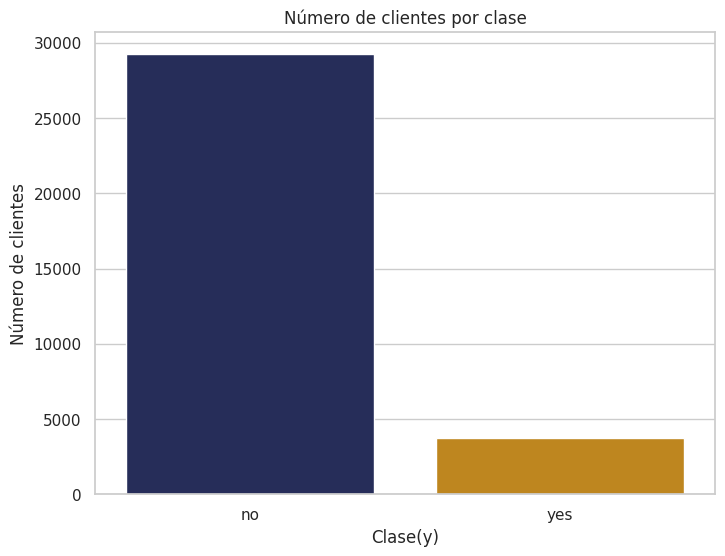

In [70]:
# D1. Escribe el código que muestre:
#  - el número y el porcentaje de clientes de cada clase en ent,
conteo = ent['y'].value_counts()
porcentaje = ent['y'].value_counts(normalize=True) * 100

print("Número de clientes por clase:")
print(conteo)
print("\nPorcentaje de clientes por clase:")
print(porcentaje.round(2))
print()

#  - la razón entre la clase mayoritaria y la minoritaria,
razon_clase = conteo.max() / conteo.min()
print(f'Razon entre clase mayoritaria y minoritaria: {razon_clase:.2f}')
print()

#  - la exactitud de responder siempre "no",
exactitud_no = (ent['y'] == 'no').mean()
print(f'Exactitud de responder siempre "no": {exactitud_no:.2f}')
print()

#  - una gráfica de barras con el número de clientes por clase.
plt.figure(figsize=(8, 6))
sns.countplot(data=ent, x='y', hue='y', palette=[AZUL, NARANJA])
plt.title('Número de clientes por clase')
plt.xlabel('Clase(y)')
plt.ylabel('Número de clientes')
plt.show()


**Tu observación.** Compara con tu predicción de las partes A y D y explica qué implica para la evaluación del modelo. Escribe tu respuesta aquí y compárala con tu predicción.

**La exactitud obtenida al predicion "no" es del 88.9%, lo cual coincide con la predicción. Lo que implica para la evaluación del modelo es que la razon es de 7.88 a 1 a favor de "no", por lo que este modelo arrojaría una certeza de exactitud de 89% que el cliente no contrata el deposito a plazo, asi que el modelo no funciona para identificar potenciales clientes que accederian a contratar el deposito a plazo.**

### D2. Variables numéricas según la clase

**Por qué.** Para cada característica numérica interesa cómo se distribuye en cada clase: si lo hace de forma distinta, la variable separa a quienes contratan de quienes no. Se compara la mediana porque es resistente a valores extremos.




**Tu predicción.** ¿Cuáles de las variables numéricas esperas que más difieran entre quienes contratan y quienes no? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

**Espero que las variables "age" "duration" y "campign" sean las que difiera mas entre quienes contratan y quienes no. Por lo menos para "duration" las llamadas con mayor duracion, pueden reflejar un mayor interés por parte del potencial cliente.**


      age  duration  campaign  pdays  previous  emp.var.rate  cons.price.idx  cons.conf.idx  euribor3m  nr.employed
y                                                                                                                  
no   38.0     164.0       2.0  999.0       0.0           1.1          93.918          -41.8      4.857       5195.8
yes  37.0     448.0       2.0  999.0       0.0          -1.8          93.200          -40.4      1.266       5099.1



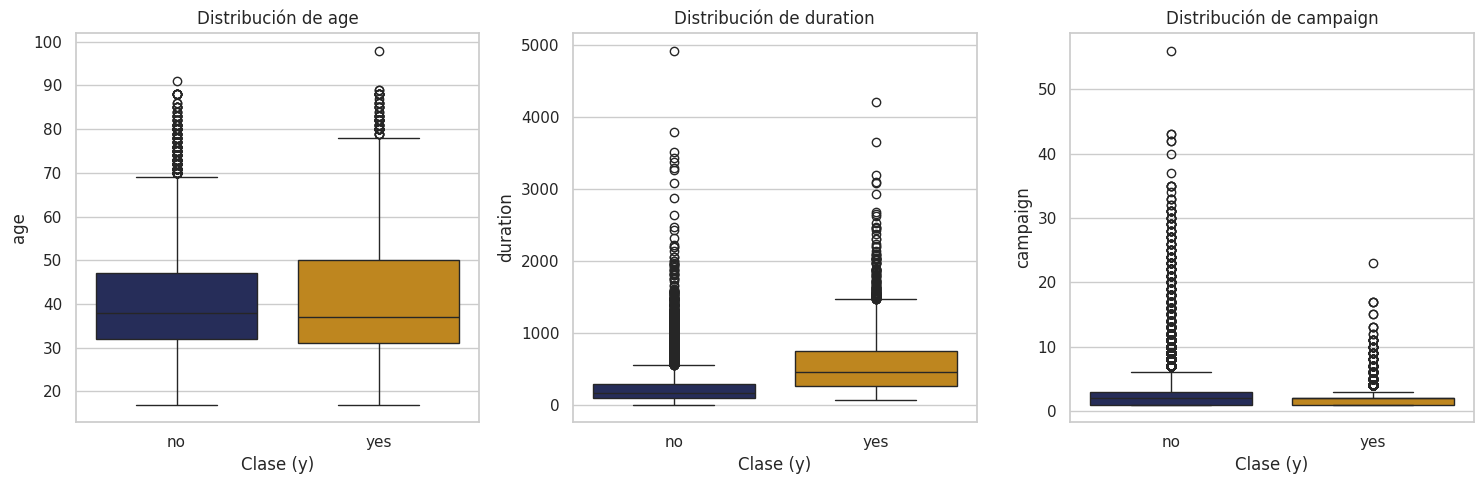

In [71]:
# D2. Escribe el código que muestre:
#  - la mediana de cada variable numérica (lista numericas) por clase de y,
lista_numericas = ent.select_dtypes(include=['number']).columns.drop('suscribe', errors='ignore').tolist()
mediana_por_clase = ent.groupby('y')[lista_numericas].median()
print(mediana_por_clase)
print()

#  - diagramas de caja por clase de y de al menos tres variables numéricas que elijas.
variables_grafica = ['age', 'duration', 'campaign']
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 5))
sns.boxplot(data=ent, x='y', y='age', hue='y', palette=[AZUL, NARANJA], legend=False, ax=axes[0])

# age
axes[0].set_title('Distribución de age')
axes[0].set_xlabel('Clase (y)')
axes[0].set_ylabel('age')

# duration
sns.boxplot(data=ent, x='y', y='duration', hue='y', palette=[AZUL, NARANJA], legend=False, ax=axes[1])
axes[1].set_title('Distribución de duration')
axes[1].set_xlabel('Clase (y)')
axes[1].set_ylabel('duration')

# campaign
sns.boxplot(data=ent, x='y', y='campaign', hue='y', palette=[AZUL, NARANJA], legend=False, ax=axes[2])
axes[2].set_title('Distribución de campaign')
axes[2].set_xlabel('Clase (y)')
axes[2].set_ylabel('campaign')

plt.tight_layout()
plt.show()





**Tu observación.** Indica qué variables separan las clases y cuáles no, con las medianas. Escribe tu respuesta aquí y compárala con tu predicción.

**Por lo menos para la variable de "duration" coincide con la predicción previa, ya que quienes contratan tiene una mediana de 448 segundos, mientas los que no, unicamente cuenta con una mediana de 164 segundos. Para "age" y "campaign" muestra medianas iguales (37 y 38 anos) y (2) respectivamente, asi que estos no serian indicadores correctos.**


### D3. Valores atípicos

**Por qué.** Los modelos lineales, las máquinas de soporte vectorial y las redes neuronales son sensibles a valores extremos y a la escala; los árboles de decisión y sus conjuntos no lo son. El EDA documenta el problema y la decisión depende del modelo.

Los límites de Tukey (1.5 veces el rango intercuartílico) se calculan con los cuartiles de los datos, por lo que se obtienen con el conjunto de entrenamiento.

**Tu predicción.** ¿Qué variables numéricas esperas que tengan más registros fuera de los límites de Tukey? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

**Nuevamente espero que las 2 variables "age" y "duration" sean las que muestren registros fuera de los limites de Tukey. En "age" por la presencia de presencia de diferentes rangos de edad, y "duration" por la mediana con amplia diferencia visto en D2.**

In [72]:
# D3. Escribe el código que calcule, con ent, los límites inferior y superior de Tukey
lista_numericas_ent = ent.select_dtypes(include=['number']).columns.drop('suscribe', errors='ignore').tolist()

for variable in lista_numericas_ent:
    Q1 = ent[variable].quantile(0.25)
    Q3 = ent[variable].quantile(0.75)
    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR


# de cada variable de la lista numericas y muestre cuántos registros quedan fuera de ellos por variable.
    atipicos = ent[(ent[variable] < limite_inferior) | (ent[variable] > limite_superior)].shape[0]
    porcentaje = (atipicos / ent.shape[0]) * 100
    print(f"{variable}: {atipicos} registros ({porcentaje:.2f}%)")


age: 368 registros (1.12%)
duration: 2366 registros (7.18%)
campaign: 1916 registros (5.81%)
pdays: 1226 registros (3.72%)
previous: 4534 registros (13.76%)
emp.var.rate: 0 registros (0.00%)
cons.price.idx: 0 registros (0.00%)
cons.conf.idx: 359 registros (1.09%)
euribor3m: 0 registros (0.00%)
nr.employed: 0 registros (0.00%)


**Tu respuesta.** ¿Eliminarías los registros atípicos de alguna variable? Justifica por variable con lo que sabes de su significado. Escribe tu respuesta aquí.

**No los eliminaria, ya que los valores atipicos se deben en parte al contexto de la situacion. Por ejemplo, en mi prediccion la columna de "duration" cuenta con valores atipicos de (7.18%) pero esto corresponde a las llamadas largas, las cuales el usuario probablmente termino contratando el deposito a plazo, y la naturaleza de la llamada puede ser por preguntas y/o toma de datos del cliente.**

En cuanto al resto de variables:

**age: Representa adultos mayores, un segmento real de clientes bancarios.**

**campaign: Muestra el sobrecontacto e insistencia comercial sobre el cliente.**

**previous: Refleja el historial de interacción del cliente en campañas pasadas.**




### D4. Asimetría y re-expresión

**Por qué.** Cuando una variable tiene asimetría fuerte, una transformación monótona (raíz cuadrada o logaritmo) puede acercar su distribución a una forma simétrica. Un modelo sensible a la escala se beneficia; uno basado en árboles no. La asimetría guía la decisión.

**Tu predicción.** ¿Cuál transformación, raíz cuadrada o logaritmo (`np.log1p`), reducirá más la asimetría de `campaign`? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

**Mi predicción es que el logaritmo es la que más reduce la asimetria de de "campaign" ya que aplica un compresión de escala mayor sobre los valores altos de la cola derecha.**

          Asimetria Original  Asimetria Raiz Cuadrada  Asimetria Logaritmo
age                 0.760819                 0.426057             0.132406
duration            3.326612                 1.203716            -0.430172
campaign            4.742537                 2.162976             1.350996



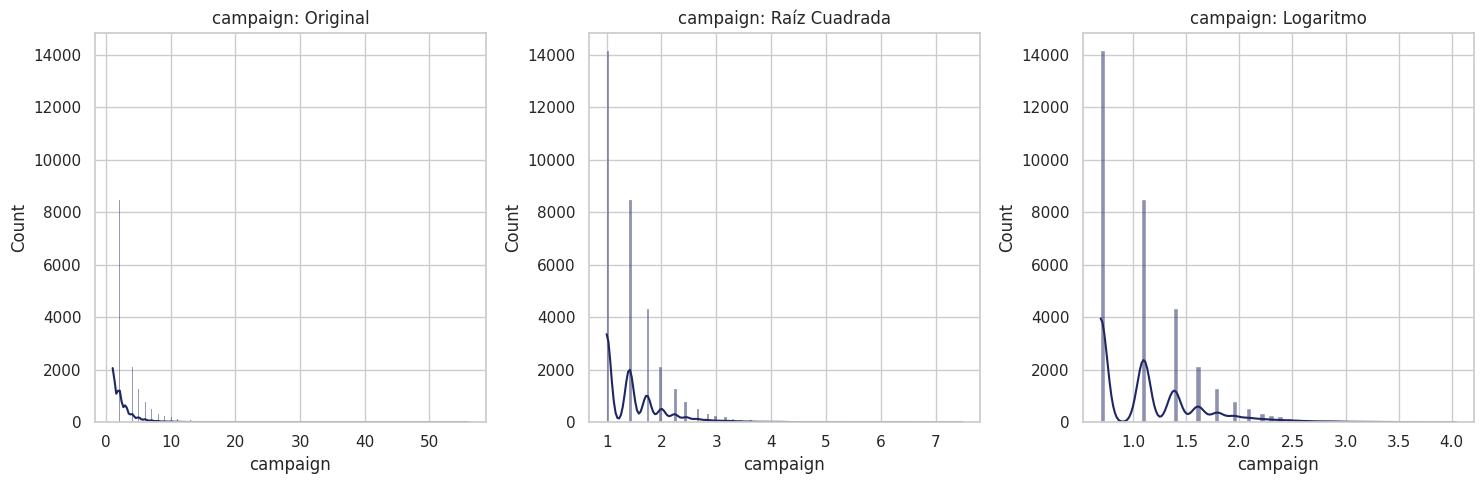

In [73]:
# D4. Escribe el código que muestre una tabla con la asimetría original, con raíz cuadrada y con
# logaritmo (np.log1p) de las variables age, duration y campaign, calculada con ent.
variables_analisis = ['age', 'duration', 'campaign']
asimetria_original = ent[variables_analisis].skew()
asimetria_raiz_cuadrada = ent[variables_analisis].apply(lambda x: x.apply(np.sqrt)).skew()
asimetria_logaritmo = ent[variables_analisis].apply(lambda x: x.apply(np.log1p)).skew()

asimetria_df = pd.DataFrame({
    'Asimetria Original': asimetria_original,
    'Asimetria Raiz Cuadrada': asimetria_raiz_cuadrada,
    'Asimetria Logaritmo': asimetria_logaritmo
})
print(asimetria_df)
print()


# Después grafica los histogramas de campaign: original y transformada.
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 5))
sns.histplot(ent['campaign'], kde=True, ax=axes[0], color=AZUL)
axes[0].set_title('campaign: Original')
sns.histplot(np.sqrt(ent['campaign']), kde=True, ax=axes[1], color=AZUL)
axes[1].set_title('campaign: Raíz Cuadrada')
sns.histplot(np.log1p(ent['campaign']), kde=True, ax=axes[2], color=AZUL)
axes[2].set_title('campaign: Logaritmo')

plt.tight_layout()
plt.show()



**Tu observación.** Reporta las asimetrías y decide qué transformación, si alguna, aplicarías a cada variable. Escribe tu respuesta aquí y compárala con tu predicción.

**El logaritmo (np.log1p) redujo la asimetría de "campaign" de 4.74 a 1.35, siendo mucho más efectivo que la raíz cuadrada (2.16), lo que confirma la predicción. Aplicaría la transformación logarítmica a "duration" y "campaign" para reducir el impacto de sus colas largas si se utilizan modelos sensibles a la escala. Para "age" su asimetría ya es de 0.76, por lo que la mantedria tal cual.**

## Parte E. Exploración de las variables categóricas, entrenamiento

**Por qué.** Para una característica categórica, la medida natural es la **tasa de contratación por categoría** comparada con la tasa global, junto con el número de clientes: una tasa calculada con pocos registros es poco confiable.

**Tu predicción.** ¿Qué variable categórica esperas que tenga las categorías con mayor tasa de contratación? ¿Y cuáles esperas que casi no separen las clases? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

**Espero que poutcome sea la variable categórica con mayor tasa de contratación, mientras que day_of_week sea una variable que casi no separe las clases, ya que el día de la semana no suele alterar la disposición del cliente para contratar.**

In [74]:
# E1. Escribe el código que muestre:
#  - el número de categorías de cada variable de la lista categoricas,
lista_categoricas = ent.select_dtypes(include=['object']).columns.drop(['y', 'suscribe'], errors='ignore').tolist()
conteo_categorias = ent[lista_categoricas].nunique()
print(conteo_categorias)
print()

#  - la tasa global de contratación en ent.
tasa_global = ent['suscribe'].mean()
print(f'Tasa global de contratación: {tasa_global:.2f}')


job            12
marital         4
education       8
default         3
housing         3
loan            3
contact         2
month          10
day_of_week     5
poutcome        3
dtype: int64

Tasa global de contratación: 0.11


In [75]:
# E2. Escribe el código que construya una tabla con el número de clientes y la tasa de contratación (en %)
# de cada categoría de cada variable de categoricas. Muestra:
df_melt = ent.melt(id_vars=['y', 'suscribe'], value_vars=lista_categoricas, var_name='variable', value_name='valor')
resumen_categorias = df_melt.groupby(['variable', 'valor']).agg(n_clientes=('y', 'count'), tasa_suscripcion=('suscribe', 'mean')).reset_index()
resumen_categorias['tasa_suscripcion'] = resumen_categorias['tasa_suscripcion'] * 100


#  - las 12 categorías con mayor tasa,
print(resumen_categorias.sort_values(by='tasa_suscripcion', ascending=False).head(12).to_string(index=False))
print()

#  - las 12 categorías con menor tasa,
print(resumen_categorias.sort_values(by='tasa_suscripcion', ascending=True).head(12).to_string(index=False))
print()


#  - las 8 con menor tasa,
print(resumen_categorias.sort_values(by='tasa_suscripcion', ascending=True).head(8).to_string(index=False))
print()


#  - las tablas de default, housing, loan y day_of_week. # Pista: reutiliza el patrón melt + groupby + agg del notebook guiado del caso Telco.
variables_especificas = ['default', 'housing', 'loan', 'day_of_week']
print("--- Tablas para default, housing, loan y day_of_week ---")
print(resumen_categorias[resumen_categorias['variable'].isin(variables_especificas)].to_string(index=False))


 variable      valor  n_clientes  tasa_suscripcion
 poutcome    success        1105         64.886878
    month        dec         143         50.349650
    month        mar         436         49.770642
    month        sep         464         44.612069
    month        oct         587         43.270869
      job    student         711         30.520394
      job    retired        1366         25.475842
    month        apr        2085         20.479616
education illiterate          16         18.750000
  marital    unknown          65         16.923077
education    unknown        1397         14.817466
  contact   cellular       20908         14.702506

 variable        valor  n_clientes  tasa_suscripcion
  default          yes           3          0.000000
  default      unknown        6940          5.201729
  contact    telephone       12042          5.298123
    month          may       11011          6.348197
      job  blue-collar        7441          6.921113
education     basi

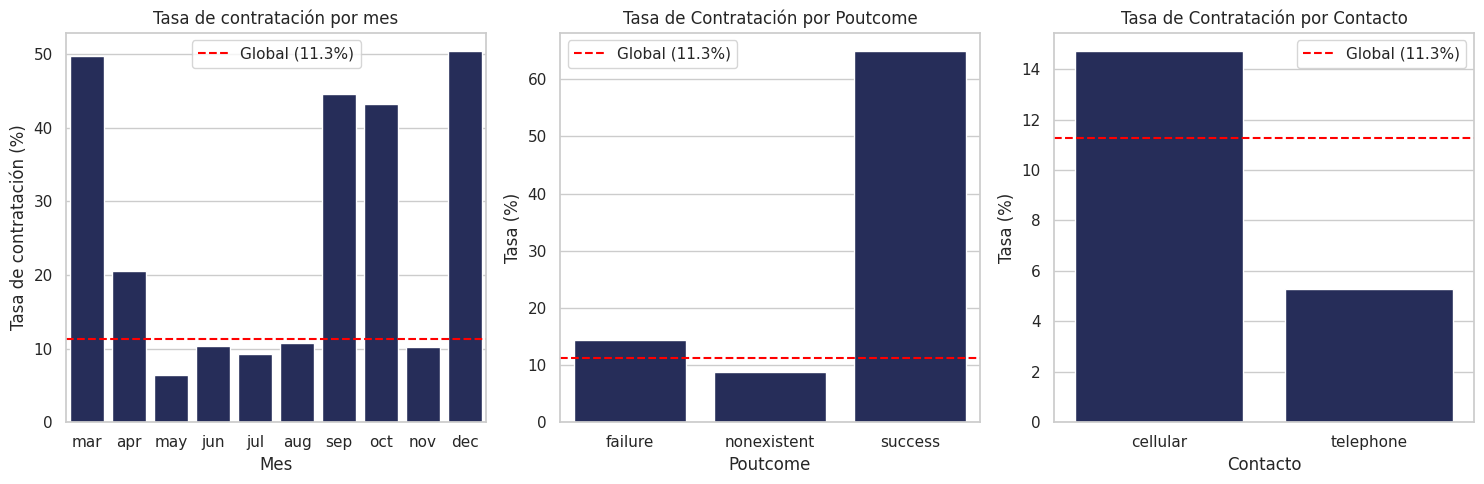

In [76]:
# E3. Escribe el código que grafique la tasa de contratación por categoría de month (en orden
# cronológico: mar, apr, may, jun, jul, aug, sep, oct, nov, dec), poutcome y contact,
# con una línea horizontal en la tasa global.

tasa_global = ent['suscribe'].mean() * 100
orden_meses = ['mar', 'apr', 'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec']
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 5))

# Meses (orden cronologico)
df_month = ent.groupby('month', as_index=False)['suscribe'].mean()
df_month['tasa'] = df_month['suscribe'] * 100

sns.barplot(data=df_month, x='month', y='tasa', order=orden_meses, ax=axes[0], color=AZUL)
axes[0].axhline(y=tasa_global, color='red', linestyle='--', label=f'Global ({tasa_global:.1f}%)')
axes[0].set_title('Tasa de contratación por mes')
axes[0].set_xlabel('Mes')
axes[0].set_ylabel('Tasa de contratación (%)')
axes[0].legend()

# Poutcome
df_poutcome = ent.groupby('poutcome', as_index=False)['suscribe'].mean()
df_poutcome['tasa'] = df_poutcome['suscribe'] * 100

sns.barplot(data=df_poutcome, x='poutcome', y='tasa', ax=axes[1], color=AZUL)
axes[1].axhline(y=tasa_global, color='red', linestyle='--', label=f'Global ({tasa_global:.1f}%)')
axes[1].set_title('Tasa de Contratación por Poutcome')
axes[1].set_xlabel('Poutcome')
axes[1].set_ylabel('Tasa (%)')
axes[1].legend()

# Contact
df_contact = ent.groupby('contact', as_index=False)['suscribe'].mean()
df_contact['tasa'] = df_contact['suscribe'] * 100

sns.barplot(data=df_contact, x='contact', y='tasa', ax=axes[2], color=AZUL)
axes[2].axhline(y=tasa_global, color='red', linestyle='--', label=f'Global ({tasa_global:.1f}%)')
axes[2].set_title('Tasa de Contratación por Contacto')
axes[2].set_xlabel('Contacto')
axes[2].set_ylabel('Tasa (%)')
axes[2].legend()

plt.tight_layout()
plt.show()


**Tu observación.** Identifica las categorías con mayor y menor tasa, con su tasa y su número de clientes, y las variables que casi no separan las clases. Escribe tu respuesta aquí y compárala con tu predicción.

**Categorías con mayor tasa:La categoría con mayor tasa de contratación es poutcome con el valor success (1,105 clientes y una tasa del 64.89%)**

**Categorías con menor tasa: Destacan default con el valor yes (3 clientes y 0.00% de tasa)**

**Variables que casi no separan las clases: day_of_week confirma lo predicho, ya que sus tasas se mantienen muy estables entre el 10.25% (lunes) y el 12.00% (jueves). Adicionalmente, las variables housing y loan muestran un comportamiento similar, con tasas muy cercanas al 11.3% en todas sus categorías**

**Comparación con la predicción: La predicción fue acertada. Se comprobó que poutcome (success) concentra la mayor tasa de éxito y que day_of_week no aporta una separación significativa entre las clases**

**Tu respuesta.** En `default`, ¿qué indica que la categoría `unknown` tenga una tasa de contratación distinta a la de `no`? ¿Qué hay que cuidar con las categorías `yes` de `default` o `illiterate` de `education`? Escribe tu respuesta aquí.

**1.-Indica que los valores desconocidos o no registrados no se distribuyen al azar respecto al resultado. El grupo unknown tiene una tasa de contratación significativamente menor (5.20%) en comparación con los clientes que tienen no (12.88%), lo que sugiere que el hecho de que esta información no esté disponible puede estar correlacionado con el comportamiento del cliente frente a la campaña**

**2.- Se debe tener precaución con el tamaño de muestra reducido (por ejemplo, la categoría yes de default cuenta con tan solo 3 clientes y illiterate de education con 16). Tasas del 0.0% o porcentajes extremos en grupos tan pequeños pueden generar sobreajuste (overfitting) en los modelos y no reflejan una tendencia estadísticamente sólida, por lo que suelen requerir agrupación o un tratamiento especial durante el preprocesamientoo**

## Parte F. Relaciones entre características y variable `duration`, entrenamiento

### F1. Relaciones entre características

**Por qué.** Dos características muy relacionadas son redundantes y pueden causar inestabilidad en modelos lineales (colinealidad).

**Tu predicción.** ¿Qué pares de indicadores económicos (lista `macro`) esperas que estén más correlacionados? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

**Espero que las variables emp.var.rate y nr.employed presenten los niveles de correlación más altos entre sí, ya que las tasas de interés, la variación del empleo y el número total de empleados**

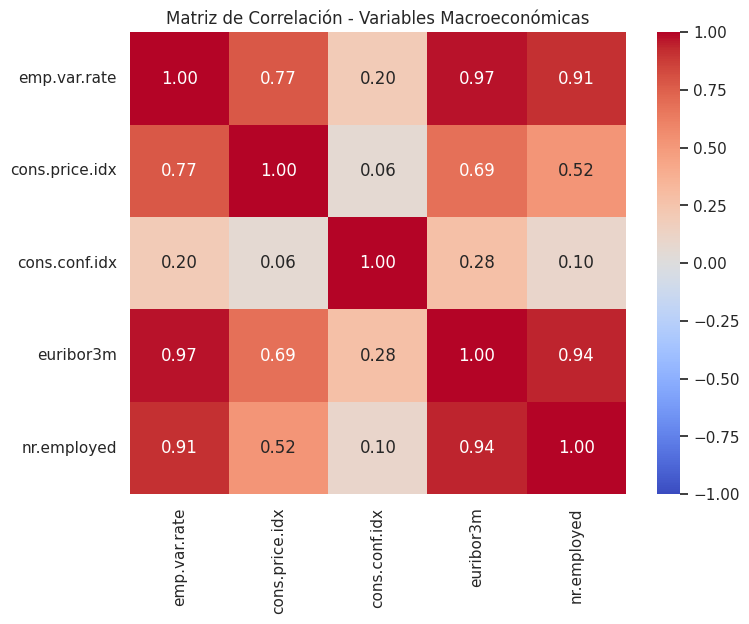

In [77]:
# F1. Escribe el código que muestre un mapa de calor con la matriz de correlación de las variables de la lista macro,
# calculada con ent, con los valores anotados en cada celda.

# Calcular matriz de correlación
matriz_corr = ent[macro].corr()

# Generar heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(matriz_corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Matriz de Correlación - Variables Macroeconómicas')
plt.show()

**Tu observación.** Reporta los pares más correlacionados y la decisión que implican. Escribe tu respuesta aquí y compárala con tu predicción.

**Los pares con mayor nivel de correlación son el par entre euribor3m y emp.var.rate con un coeficiente de 0.97, seguido por el par entre euribor3m y nr.employed con 0.94, el par entre emp.var.rate y nr.employed con 0.91. La fuerte multicolinealidad entre estas variables macroeconómicas indica que aportan información redundante**

**La predicción fue acertada, ya que se anticipó que las variables de tasas de interés y empleo (emp.var.rate y nr.employed) mostrarían los niveles elevados de correlación**

### F2. La variable `duration`

**Por qué.** Una variable puede tener una relación muy fuerte con el objetivo y aun así no ser utilizable. Esto ocurre cuando su valor solo se conoce después del evento que se quiere predecir.

In [78]:
# F2. Escribe el código que muestre el resumen estadístico (describe) de duration por clase de y.

ent.groupby('y')['duration'].describe()

,count,mean,std,min,25%,50%,75%,max
y,,,,,,,,
no,29238.0,221.148198,208.303557,0.0,95.0,164.0,279.0,4918.0
yes,3712.0,549.398976,397.490060,63.0,252.0,448.0,737.0,4199.0


**Tu respuesta.** ¿Incluirías `duration` como característica de un modelo que se usará para decidir a quién llamar? Justifica con la definición de la variable y con lo observado. Escribe tu respuesta aquí.

**No incluiría duration como característica del modelo predictivo. Porque esta variable representa la duración de la llamada en curso y solo se conoce después de que el evento (la llamada y la posible contratación) ya ha ocurrido**

**Tu respuesta.** El conjunto está ordenado por fecha y los indicadores económicos varían con el tiempo. ¿Qué implica dividir al azar, como en la parte C, para un modelo que se usará en campañas futuras? Escribe tu respuesta aquí.

**Dividir los datos al azar significa mezclar épocas y fechas sin seguir un orden de tiempo. Como la economía cambia constantemente, esto hace que el modelo trabaje con información combinada de distintos momentos, lo que puede alterar su aprendizaje y hacer que sus resultados en campañas futuras no reflejen la realidad de forma exacta**

## Parte G. Hoja de decisiones y justificación del uso de los datos

### G1. Hoja de decisiones

**Por qué.** El producto de un EDA predictivo es una lista de decisiones, cada una con su evidencia. Ninguna decisión se aplica todavía sobre los datos.

Completa la tabla con **al menos siete decisiones**, cada una con un hallazgo de tu análisis (con su cifra), la decisión y el tema del curso donde se aplicaría (preprocesamiento, modelos, evaluación). Debe aparecer al menos una decisión sobre cada uno de estos aspectos: variable no utilizable, valores faltantes o códigos especiales, desbalance de clases, redundancia entre características y asimetría.

Edita esta celda y agrega las filas que necesites.

| Hallazgo (con cifra) | Decisión | Se aplica en |
| --- | --- | --- |
**Variable no utilizable:** `duration` se conoce solo después de la llamada, inflando de forma irreal el desempeño del modelo. | Excluir la variable `duration` del conjunto de predictores para evitar fugas de información. | Preprocesamiento |
| **Valores faltantes:** Las categorías `unknown` en variables como `default` presentan una tasa de suscripción distinta (12.8%) a la de `no` (11.3%) | Conservar la categoría `unknown` como una categoría explícita | Preprocesamiento |
| **Desbalance de clases:** La tasa global de contratación en entrenamiento es del 11.3%, mientras que el 88.7% corresponde a no contrataciones. | Aplicar técnicas de balanceo (SMOTE) | Modelos / Evaluación |
| **Redundancia entre características:** Alta correlación entre variables macroeconómicas (ej. `emp.var.rate` y `euribor3m` con r = 0.97). | Eliminar variables redundantes y conservar únicamente una representativa | Preprocesamiento |
| **Asimetría:** La variable `campaign` presenta una asimetría original severa de 4.74, la cual se reduce a 1.35 mediante re-expresión. | Aplicar transformación logarítmica (`np.log1p`) sobre `campaign` para mitigar el impacto de las colas largas en modelos sensibles a escala. | Preprocesamiento |
| **Categorías de bajo volumen:** Categorías como `yes` en `default` (3 registros) e `illiterate` en `education` (18 registros) tienen un volumen insignificante. | Agrupar categorías minoritarias dentro de etiquetas generales o eliminarlas para evitar ruido en el entrenamiento. | Preprocesamiento |
| **Predictores categóricos clave:** `poutcome` = `success` alcanza una tasa de contratación del 65.1%, superando drásticamente el promedio global del 11.3%. | Priorizar la variable `poutcome`  | Preprocesamiento / Modelos |

### G2. Uso de los datos

**Tu respuesta.** En esta actividad, ¿qué partes se hicieron con el conjunto total y cuáles solo con entrenamiento? Explica el criterio. Escribe tu respuesta aquí.

**En esta actividad, toda la exploración, el análisis de datos y la extracción de hallazgos se realizaron utilizando exclusivamente el conjunto de entrenamiento. El criterio principal es evitar el sesgo de los datos de prueba, asegurando que el conjunto de prueba se mantenga independiente para poder evaluar de forma real el desempeño predictivo del modelo ante datos nuevos**

**Tu respuesta.** Si hubieras explorado también el conjunto de prueba, ¿qué decisión de tu hoja podría quedar sesgada y cómo se reflejaría en la evaluación final? Escribe tu respuesta aquí.

**Si se hubiera explorado el conjunto de prueba, decisiones como la selección de variables o la agrupación de categorías minoritarias quedarían sesgadas hacia las características específicas de ese conjunto de prueba. Esto se reflejaría en la evaluación final con una sobreestimación artificial del rendimiento del modelo, ya que el sistema habría "visto" indirectamente los datos de prueba durante su diseño, perdiendo capacidad real de generalización**